# Análise de Redes Complexas: Centralidades da Topologia

Este notebook carrega o grafo gerado pelo modelo de Waxman, calcula as principais métricas de centralidade e consolida tudo em um `DataFrame` (`df_centralidades`) junto aos metadados físicos de cada torre para facilitar análises e plotagens.

In [17]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [18]:
# Carrega o grafo convertendo os IDs dos nós para int (alinhado ao node_id)
G = nx.read_graphml("../data/processed/grafo_se.graphml", node_type=int)

print(f"Grafo carregado -> Nós: {G.number_of_nodes():,} | Arestas: {G.number_of_edges():,}")

Grafo carregado -> Nós: 747 | Arestas: 11,618


In [19]:
# Garante que estamos trabalhando no maior componente conexo (necessário para closeness e distâncias)
largest_cc = max(nx.connected_components(G), key=len)
G = G.subgraph(largest_cc).copy()
print(f"Maior componente conexo -> Nós: {G.number_of_nodes():,} | Arestas: {G.number_of_edges():,}")

Maior componente conexo -> Nós: 747 | Arestas: 11,618


## Cálculo das Centralidades

Cada métrica captura um papel estrutural diferente das torres na rede:

1. **Centralidade de Grau (`degree_centrality` / `grau_absoluto`)**:
   - *O que mede:* Fração (ou quantidade absoluta) de conexões diretas que uma torre possui.
   - *O que diz na rede:* Identifica **hubs locais e regiões densas**. Torres com grau alto têm muitos enlaces diretos com vizinhas próximas, oferecendo maior redundância local.
2. **Centralidade de Proximidade (`closeness_centrality`)**:
   - *O que mede:* O inverso da distância média (em saltos) de uma torre até todas as outras da rede.
   - *O que diz na rede:* Mede a **eficiência de alcance global**. Torres com alta proximidade ficam topologicamente no "centro" do grafo e alcançam qualquer outro ponto da rede em menos saltos.
3. **Centralidade de Intermediação (`betweenness_centrality`)**:
   - *O que mede:* Proporção de caminhos mínimos entre todos os pares de torres que passam obrigatoriamente por aquela torre.
   - *O que diz na rede:* Identifica **pontes críticas e gargalos de roteamento** (por exemplo, torres que ligam o interior à região metropolitana). Se uma torre de alta intermediação falhar, o tráfego precisa dar voltas bem maiores.
4. **Centralidade de Autovetor (`eigenvector_centrality`)**:
   - *O que mede:* Importância de uma torre baseada na importância das torres às quais ela se conecta.
   - *O que diz na rede:* Identifica quem faz parte do **núcleo principal (backbone denso)** da rede. Uma torre conectada a vários hubs tem autovetor alto; uma torre com várias conexões apenas em um cluster isolado do interior terá autovetor baixo.

In [20]:
deg_cent = nx.degree_centrality(G)
closeness_cent = nx.closeness_centrality(G, distance="weight")
bet_cent = nx.betweenness_centrality(G, weight="weight")
eig_cent = nx.eigenvector_centrality(G, max_iter=500)

print("Centralidades calculadas com sucesso!")

Centralidades calculadas com sucesso!


## Consolidação no DataFrame (`df_centralidades`)

Agrupamos todas as centralidades com os atributos físicos de cada nó (`id_local`, `latitude`, `longitude`, `qtd_antenas`, `operadoras`, `tem_5g`) para facilitar ordenações, cruzamentos e gráficos.

In [21]:
dados_centralidade = []

for node, attrs in G.nodes(data=True):
    dados_centralidade.append({
        "node_id": node,
        "id_local": attrs.get("id_local"),
        "latitude": attrs.get("latitude"),
        "longitude": attrs.get("longitude"),
        "qtd_antenas": attrs.get("qtd_antenas"),
        "operadoras": attrs.get("operadoras"),
        "tem_5g": attrs.get("tem_5g"),
        "grau_absoluto": G.degree(node),
        "centralidade_grau": deg_cent[node],
        "centralidade_proximidade": closeness_cent[node],
        "centralidade_intermediacao": bet_cent[node],
        "centralidade_autovetor": eig_cent[node],
    })

df_centralidades = pd.DataFrame(dados_centralidade)
df_centralidades = df_centralidades.sort_values(by="centralidade_autovetor", ascending=False).reset_index(drop=True)

print(f"DataFrame criado com {len(df_centralidades):,} linhas e {df_centralidades.shape[1]} colunas.")
display(df_centralidades.head(10))

DataFrame criado com 747 linhas e 12 colunas.


,node_id,id_local,latitude,longitude,qtd_antenas,operadoras,tem_5g,grau_absoluto,centralidade_grau,centralidade_proximidade,centralidade_intermediacao,centralidade_autovetor
0,406,1016349430,-10.940352,-37.050833,3,TIM,True,83,0.111260,0.025449,0.009482,0.077134
1,293,1014810172,-10.937663,-37.070563,6,BRISANET,True,82,0.109920,0.025792,0.003994,0.075479
2,399,1014810318,-10.943909,-37.084063,6,BRISANET,True,85,0.113941,0.025587,0.009407,0.074706
3,197,1003629927,-10.911028,-37.051083,54,VIVO,True,77,0.103217,0.025737,0.004308,0.074075
4,420,442403151,-10.924639,-37.067389,21,TIM,True,77,0.103217,0.025991,0.008961,0.073941
5,422,1001378536,-10.913890,-37.049720,18,TIM,True,74,0.099196,0.025705,0.005945,0.072134
6,333,684142970,-10.924000,-37.066800,66,CLARO,True,78,0.104558,0.025980,0.004523,0.071667
7,119,1009143074,-10.951667,-37.072806,12,TIM,True,76,0.101877,0.025503,0.003469,0.071435
8,172,695601270,-10.925080,-37.110960,66,"TIM, VIVO",False,76,0.101877,0.025432,0.010108,0.071349
9,289,1016869999,-10.904917,-37.064233,3,TIM,True,77,0.103217,0.025909,0.007042,0.070489


In [22]:
colunas_metricas = [
    "grau_absoluto",
    "centralidade_grau",
    "centralidade_proximidade",
    "centralidade_intermediacao",
    "centralidade_autovetor",
]

print("=== Resumo Estatístico das Centralidades ===")
display(df_centralidades[colunas_metricas].describe())

print("\n=== Top 5 Torres por Intermediação (Pontes / Gargalos) ===")
display(df_centralidades.nlargest(5, "centralidade_intermediacao"))

=== Resumo Estatístico das Centralidades ===


,grau_absoluto,centralidade_grau,centralidade_proximidade,centralidade_intermediacao,centralidade_autovetor
count,747.000000,747.000000,747.000000,747.000000,7.470000e+02
mean,31.105756,0.041697,0.019085,0.005158,2.619678e-02
std,26.039479,0.034905,0.006538,0.006306,2.555957e-02
min,1.000000,0.001340,0.004687,0.000000,4.683729e-11
25%,5.000000,0.006702,0.013584,0.001180,1.853293e-04
50%,24.000000,0.032172,0.021317,0.003199,1.946009e-02
75%,56.000000,0.075067,0.025299,0.006422,5.154200e-02
max,85.000000,0.113941,0.026024,0.046296,7.713352e-02



=== Top 5 Torres por Intermediação (Pontes / Gargalos) ===


,node_id,id_local,latitude,longitude,qtd_antenas,operadoras,tem_5g,grau_absoluto,centralidade_grau,centralidade_proximidade,centralidade_intermediacao,centralidade_autovetor
583,619,1016867481,-10.320889,-37.412917,9,VIVO,False,7,0.009383,0.011201,0.046296,0.000068
448,284,1008554054,-10.698579,-37.426906,39,"CLARO, VIVO",True,17,0.022788,0.017735,0.041424,0.003644
650,28,534215343,-10.219444,-37.419722,117,"TIM, VIVO",True,5,0.006702,0.010200,0.040567,0.000001
628,696,1015855595,-11.100810,-37.820680,6,CLARO,False,6,0.008043,0.011115,0.037044,0.000006
537,733,1016681612,-10.932400,-37.654210,12,CLARO,True,7,0.009383,0.014036,0.033705,0.000781


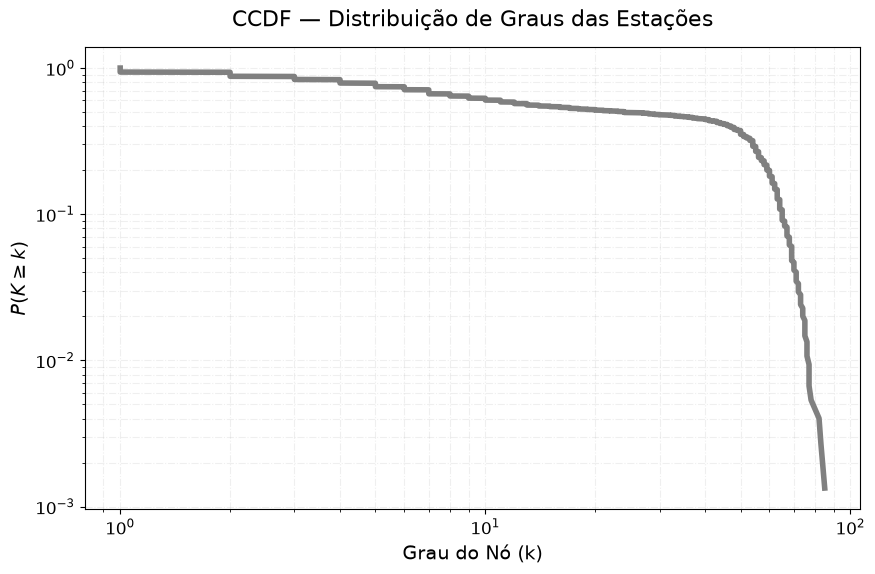

In [23]:
graus = list(dict(G.degree()).values())
sorted_graus = sorted(graus)
n=len(sorted_graus)
ccdf = 1.0 - (np.arange(n) / n)

plt.figure(figsize=(10, 6), facecolor='white')
plt.plot(sorted_graus, ccdf, linewidth=4, color='gray', label='Grau dos Nós')

plt.xscale('log')
plt.yscale('log')

plt.xlabel("Grau do Nó (k)", fontsize=14)
plt.ylabel(r"$P(K \geq k)$", fontsize=14)
plt.title("CCDF — Distribuição de Graus das Estações", fontsize=16, pad=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, which="both", linestyle="-.", alpha=0.2)

plt.show()

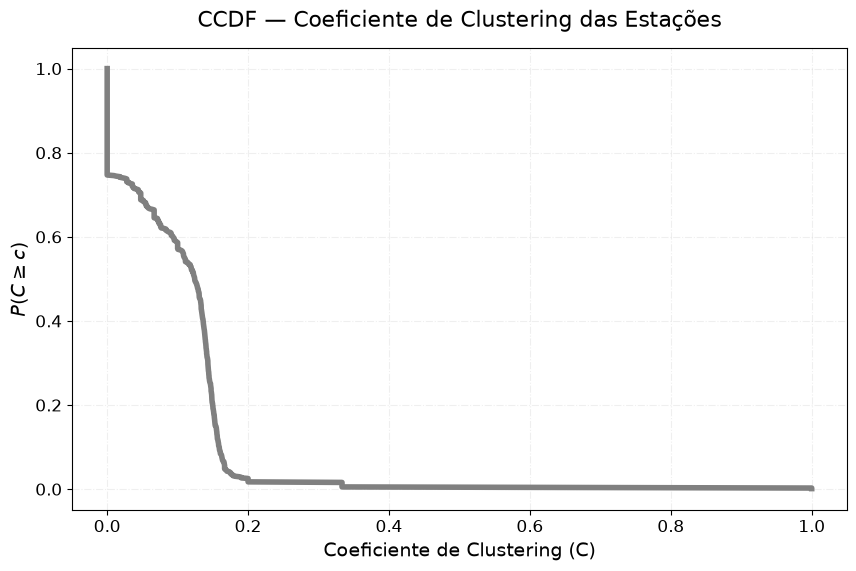

In [24]:
clustering_dict = nx.clustering(G)
clustering_values = list(clustering_dict.values())

sorted_clustering = sorted(clustering_values)
n_clustering = len(sorted_clustering)
ccdf = 1.0 - (np.arange(n_clustering) / n_clustering)

plt.figure(figsize=(10, 6), facecolor='white')

plt.plot(sorted_clustering, ccdf, linewidth=4, color='gray', label='Clustering Coef.')
plt.xlabel("Coeficiente de Clustering (C)", fontsize=14)
plt.ylabel(r"$P(C \geq c)$", fontsize=14)
plt.title("CCDF — Coeficiente de Clustering das Estações", fontsize=16, pad=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, which="both", linestyle="-.", alpha=0.2)
plt.show()

## Assortatividade de Grau ($r$) e Correlação $k_{nn}(k)$

- **Assortatividade ($r \in [-1, 1]$):** mede se nós de grau alto tendem a se conectar a outros nós de grau alto ($r > 0$, rede *assortativa*) ou a nós de grau baixo ($r < 0$, rede *disassortativa*).
- **Gráfico estilo Barabási ($k$ vs. $k_{nn}(k)$ em escala log-log):**
  - Pontos individuais ($k_{nn}$) ao fundo;
  - **Pontos roxos:** média em *bins* logarítmicos de $k$;
  - **Quadrados laranjas:** versão aleatorizada (*degree-preserving*, mantendo a mesma distribuição de graus);
  - **Linha tracejada verde:** ajuste $k_{nn}(k) = a \cdot k^{\mu}$ ($\mu > 0$ indica rede assortativa; $\mu < 0$ disassortativa; $\mu \approx 0$ neutra).

Coeficiente de Assortatividade (r): 0.4974 | Expoente de correlação (mu): 0.6821


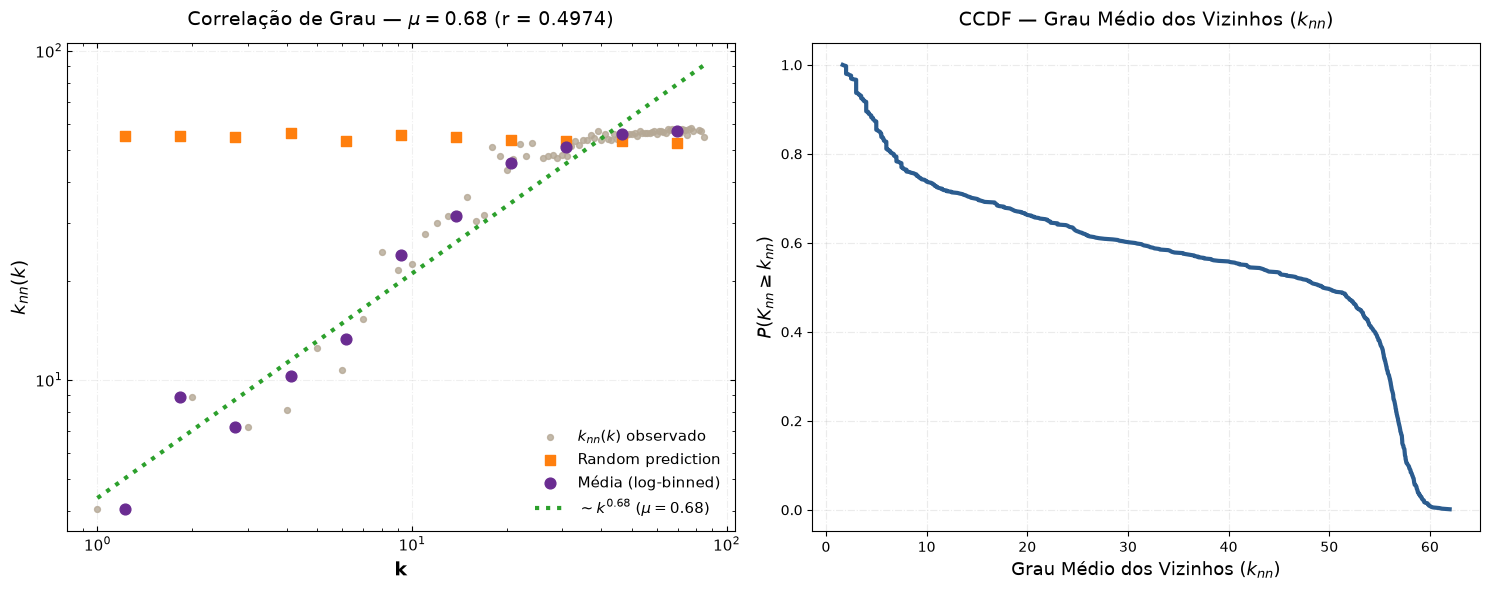

In [25]:
r_deg = nx.degree_assortativity_coefficient(G)
knn_dict = nx.average_neighbor_degree(G)
df_centralidades["grau_medio_vizinhos"] = df_centralidades["node_id"].map(knn_dict)

# 1. Versão aleatorizada preservando os graus (Random prediction, como nos slides)
G_rand = G.copy()
nx.double_edge_swap(G_rand, nswap=5 * G.number_of_edges(), max_tries=25 * G.number_of_edges(), seed=42)
knn_rand_dict = nx.average_neighbor_degree(G_rand)
k_vals = np.array([G.degree(n) for n in G.nodes()], dtype=float)
knn_vals = np.array([knn_dict[n] for n in G.nodes()], dtype=float)
knn_rand_vals = np.array([knn_rand_dict[n] for n in G.nodes()], dtype=float)

# 2. Média exata por grau k (pontos pequenos de fundo) e Log-binning (roxo / laranja)
df_knn_k = pd.DataFrame({"k": k_vals, "knn": knn_vals, "knn_rand": knn_rand_vals})
por_k = df_knn_k.groupby("k", as_index=False).mean()

bins = np.logspace(np.log10(k_vals.min()), np.log10(k_vals.max()), 12)
bin_x, bin_y, bin_rand = [], [], []
for i in range(len(bins) - 1):
    if i == len(bins) - 2:
        mask = (k_vals >= bins[i]) & (k_vals <= bins[i + 1])
    else:
        mask = (k_vals >= bins[i]) & (k_vals < bins[i + 1])
    if mask.sum() > 0:
        bin_x.append(np.sqrt(bins[i] * bins[i + 1]))
        bin_y.append(knn_vals[mask].mean())
        bin_rand.append(knn_rand_vals[mask].mean())

bin_x = np.array(bin_x)
bin_y = np.array(bin_y)
bin_rand = np.array(bin_rand)

# 3. Ajuste da lei de potência k_nn(k) = a * k^mu
mu, log_a = np.polyfit(np.log10(bin_x), np.log10(bin_y), 1)
k_fit = np.logspace(np.log10(k_vals.min()), np.log10(k_vals.max()), 100)
knn_fit = (10 ** log_a) * (k_fit ** mu)

print(f"Coeficiente de Assortatividade (r): {r_deg:.4f} | Expoente de correlação (mu): {mu:.4f}")

# 4. Plotagem estilo slide (log-log) + CCDF de k_nn
sorted_knn = np.sort(knn_vals)
n_knn = len(sorted_knn)
ccdf_knn = 1.0 - (np.arange(n_knn) / n_knn)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), facecolor="white")

# Painel 1: Gráfico idêntico ao slide
ax = axes[0]
ax.scatter(por_k["k"], por_k["knn"], s=18, color="#b5a895", alpha=0.8, label=r"$k_{nn}(k)$ observado")
ax.scatter(bin_x, bin_rand, marker="s", s=45, color="#ff7f0e", zorder=4, label="Random prediction")
ax.scatter(bin_x, bin_y, s=60, color="#6a2c91", zorder=5, label="Média (log-binned)")
ax.plot(k_fit, knn_fit, linestyle=":", linewidth=3, color="#2ca02c", zorder=6, label=rf"$\sim k^{{{mu:.2f}}}$ ($\mu={mu:.2f}$)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("k", fontsize=14, fontweight="bold")
ax.set_ylabel(r"$k_{nn}(k)$", fontsize=14, fontweight="bold")
ax.set_title(f"Correlação de Grau — $\\mu = {mu:.2f}$ (r = {r_deg:.4f})", fontsize=14, pad=12)
ax.tick_params(which="both", direction="in", top=True, right=True, labelsize=11)
ax.legend(frameon=False, fontsize=11, loc="lower right")
ax.grid(True, which="major", linestyle="-.", alpha=0.2)

# Painel 2: CCDF de k_nn
axes[1].plot(sorted_knn, ccdf_knn, linewidth=3, color="#2b5c8f")
axes[1].set_xlabel(r"Grau Médio dos Vizinhos ($k_{nn}$)", fontsize=13)
axes[1].set_ylabel(r"$P(K_{nn} \geq k_{nn})$", fontsize=13)
axes[1].set_title(f"CCDF — Grau Médio dos Vizinhos ($k_{{nn}}$)", fontsize=14, pad=12)
axes[1].grid(True, linestyle="-.", alpha=0.25)

plt.tight_layout()
plt.show()


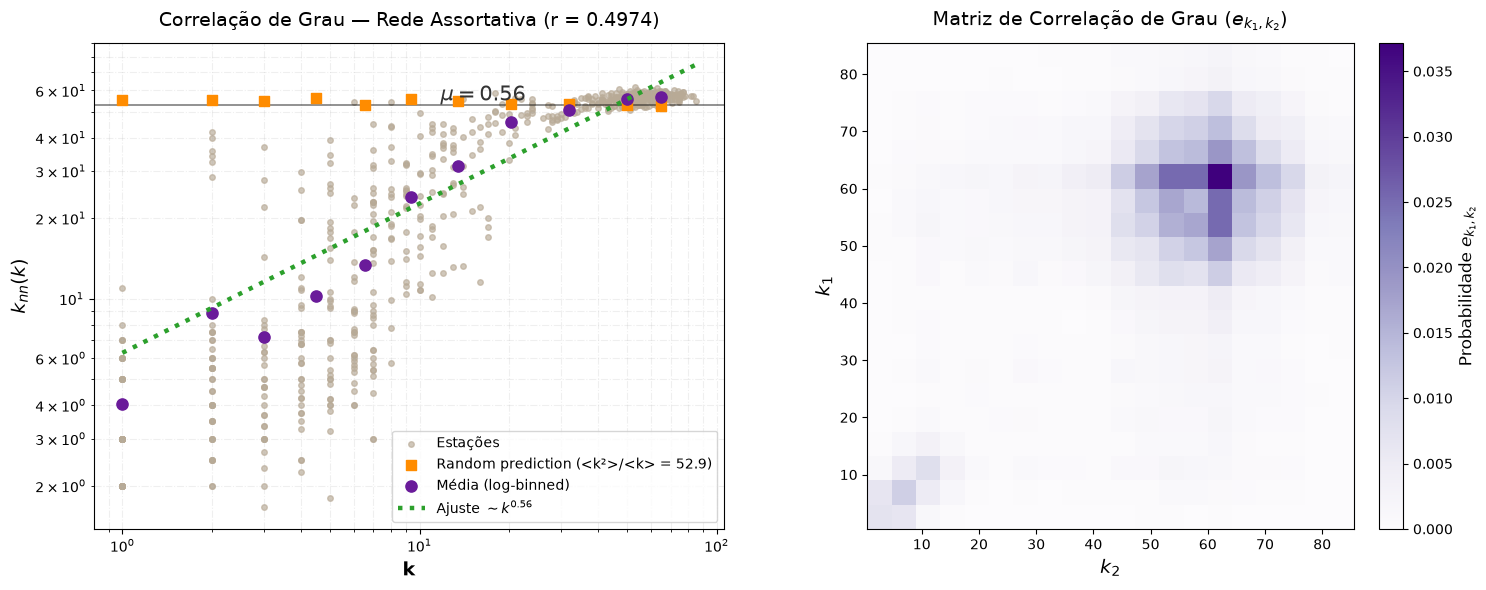

In [26]:
# Gráfico no estilo dos slides (Barabási - Network Science):
# 1) Correlação de Grau k_nn(k) em escala log-log com log-binning, Random Prediction e ajuste ~ k^mu
# 2) Matriz de Correlação e_{k1, k2} (probabilidade conjunta nas pontas das arestas)

ks = df_centralidades["grau_absoluto"].values.astype(float)
knns = df_centralidades["grau_medio_vizinhos"].values.astype(float)

# 1. Log-binning dos pontos roxos
bins = np.logspace(np.log10(ks.min()), np.log10(ks.max()), 12)
bin_k, bin_knn = [], []
for i in range(len(bins) - 1):
    mask = (ks >= bins[i]) & (ks <= bins[i + 1]) if i == len(bins) - 2 else (ks >= bins[i]) & (ks < bins[i + 1])
    if mask.sum() > 0:
        bin_k.append(ks[mask].mean())
        bin_knn.append(knns[mask].mean())
bin_k = np.array(bin_k)
bin_knn = np.array(bin_knn)

# 2. Ajuste da lei de potência k_nn(k) = a * k^mu
unique_k = np.unique(ks)
mean_knn_k = np.array([knns[ks == k].mean() for k in unique_k])
mu, log_a = np.polyfit(np.log10(unique_k), np.log10(mean_knn_k), 1)
k_fit = np.logspace(np.log10(ks.min()), np.log10(ks.max()), 100)
knn_fit = (10 ** log_a) * (k_fit ** mu)

# 3. Previsão Aleatória (Degree-Preserving Randomization mantendo os mesmos graus)
G_rand = G.copy()
nx.double_edge_swap(G_rand, nswap=5 * G.number_of_edges(), max_tries=20 * G.number_of_edges(), seed=42)
knn_rand_dict = nx.average_neighbor_degree(G_rand)
ks_rand = np.array([G_rand.degree(n) for n in G_rand.nodes()], dtype=float)
knns_rand = np.array([knn_rand_dict[n] for n in G_rand.nodes()], dtype=float)
bin_k_rand, bin_knn_rand = [], []
for i in range(len(bins) - 1):
    mask = (ks_rand >= bins[i]) & (ks_rand <= bins[i + 1]) if i == len(bins) - 2 else (ks_rand >= bins[i]) & (ks_rand < bins[i + 1])
    if mask.sum() > 0:
        bin_k_rand.append(ks_rand[mask].mean())
        bin_knn_rand.append(knns_rand[mask].mean())
knn_teorico = np.mean(ks ** 2) / np.mean(ks)

# 4. Matriz de Correlação e_{k1, k2} (simétrica para grafo não-direcionado)
k_max = int(ks.max())
n_bins_mat = 20
edges_mat = np.linspace(0.5, k_max + 0.5, n_bins_mat + 1)
u_degs = [G.degree(u) for u, v in G.edges()]
v_degs = [G.degree(v) for u, v in G.edges()]
all_k1 = np.array(u_degs + v_degs)
all_k2 = np.array(v_degs + u_degs)
H, _, _ = np.histogram2d(all_k1, all_k2, bins=[edges_mat, edges_mat])
e_ij = H / H.sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), facecolor="white")

# --- Painel Esquerdo: Gráfico clássico k_nn(k) (Barabási / Slides 28-42) ---
ax = axes[0]
ax.scatter(ks, knns, color="#b8aa96", s=16, alpha=0.65, zorder=1, label="Estações")
ax.scatter(bin_k_rand, bin_knn_rand, color="#ff8c00", marker="s", s=45, zorder=3, label=f"Random prediction (<k²>/<k> = {knn_teorico:.1f})")
ax.axhline(knn_teorico, color="black", linewidth=1.2, alpha=0.5, linestyle="-", zorder=2)
ax.scatter(bin_k, bin_knn, color="#6a1b9a", s=65, zorder=4, label="Média (log-binned)")
ax.plot(k_fit, knn_fit, color="#2ca02c", linestyle=":", linewidth=3.2, zorder=5, label=rf"Ajuste $\sim k^{{{mu:.2f}}}$")
ax.text(0.55, 0.88, rf"$\mu = {mu:.2f}$", transform=ax.transAxes, fontsize=15, color="#333333")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("k", fontsize=14, fontweight="bold")
ax.set_ylabel(r"$k_{nn}(k)$", fontsize=14, fontweight="bold")
ax.set_title(f"Correlação de Grau — Rede Assortativa (r = {r_deg:.4f})", fontsize=14, pad=12)
ax.legend(loc="lower right", frameon=True)
ax.grid(True, which="both", linestyle="-.", alpha=0.2)

# --- Painel Direito: Matriz de Correlação e_{k1, k2} (Slides 11-13) ---
ax2 = axes[1]
im = ax2.imshow(
    e_ij,
    origin="lower",
    extent=[0.5, k_max + 0.5, 0.5, k_max + 0.5],
    cmap="Purples",
    aspect="equal",
)
cbar = fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)
cbar.set_label(r"Probabilidade $e_{k_1, k_2}$", fontsize=12)
ax2.set_xlabel(r"$k_2$", fontsize=14, fontweight="bold")
ax2.set_ylabel(r"$k_1$", fontsize=14, fontweight="bold")
ax2.set_title(r"Matriz de Correlação de Grau ($e_{k_1, k_2}$)", fontsize=14, pad=12)

plt.tight_layout()
plt.show()


## Robustez da Rede (Falhas Aleatórias vs. Ataques Direcionados)

A robustez mede quanto a rede permanece conectada à medida que torres são removidas (por falha técnica ou ataque direcionado). 
- Para cada fração $ de nós removidos, medimos (f) = |LCC| / N$ (tamanho relativo do maior componente conexo).
- O **Índice de Robustez * (Schneider et al., 2011) é a área sob a curva (f)$ ( \in [0, 0.5]$ aproximadamente; quanto maior, mais resiliente).

Índice de Robustez R (Falha Aleatória):      0.4593
Índice de Robustez R (Ataque por Grau):      0.4532
Índice de Robustez R (Ataque Intermediação): 0.4005


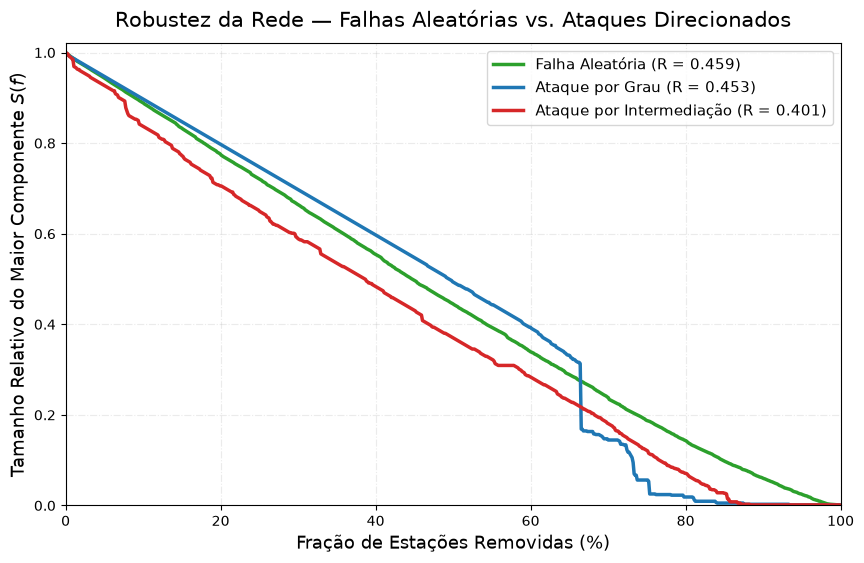

In [27]:
def simular_robustez(G_in, ordem_remocao):
    G_tmp = G_in.copy()
    N = G_in.number_of_nodes()
    s = [1.0]
    for u in ordem_remocao:
        G_tmp.remove_node(u)
        if G_tmp.number_of_nodes() == 0:
            s.append(0.0)
        else:
            lcc = len(max(nx.connected_components(G_tmp), key=len))
            s.append(lcc / N)
    return np.array(s)

N = G.number_of_nodes()
f_removido = np.linspace(0.0, 1.0, N + 1)

# 1. Ataque por Grau
ordem_grau = [n for n, _ in sorted(G.degree(), key=lambda x: x[1], reverse=True)]
s_grau = simular_robustez(G, ordem_grau)

# 2. Ataque por Intermediação (Betweenness)
ordem_bet = [n for n, _ in sorted(bet_cent.items(), key=lambda x: x[1], reverse=True)]
s_bet = simular_robustez(G, ordem_bet)

# 3. Falhas Aleatórias (média de 10 execuções)
rng = np.random.default_rng(42)
s_rand_runs = []
nodes_list = list(G.nodes())
for _ in range(10):
    ordem_rand = nodes_list.copy()
    rng.shuffle(ordem_rand)
    s_rand_runs.append(simular_robustez(G, ordem_rand))
s_rand = np.mean(s_rand_runs, axis=0)

R_rand = float(s_rand[1:].mean())
R_grau = float(s_grau[1:].mean())
R_bet = float(s_bet[1:].mean())

print(f"Índice de Robustez R (Falha Aleatória):      {R_rand:.4f}")
print(f"Índice de Robustez R (Ataque por Grau):      {R_grau:.4f}")
print(f"Índice de Robustez R (Ataque Intermediação): {R_bet:.4f}")

plt.figure(figsize=(10, 6), facecolor="white")
plt.plot(f_removido * 100, s_rand, linewidth=2.5, color="#2ca02c", label=f"Falha Aleatória (R = {R_rand:.3f})")
plt.plot(f_removido * 100, s_grau, linewidth=2.5, color="#1f77b4", label=f"Ataque por Grau (R = {R_grau:.3f})")
plt.plot(f_removido * 100, s_bet, linewidth=2.5, color="#d62728", label=f"Ataque por Intermediação (R = {R_bet:.3f})")

plt.xlabel("Fração de Estações Removidas (%)", fontsize=13)
plt.ylabel("Tamanho Relativo do Maior Componente $S(f)$", fontsize=13)
plt.title("Robustez da Rede — Falhas Aleatórias vs. Ataques Direcionados", fontsize=15, pad=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle="-.", alpha=0.25)
plt.xlim(0, 100)
plt.ylim(0, 1.02)
plt.show()

## Detecção de Comunidades (Algoritmo de Louvain)

- O algoritmo de **Louvain** particiona o grafo maximizando a **modularidade ($Q$)**, agrupando torres que possuem enlaces mais fortes entre si do que com o restante da rede.
- Como o atributo `weight` do grafo armazena a **distância física em km** (onde valores maiores indicam enlaces mais distantes), criamos o peso de **proximidade** `prox = 1.0 / (weight + 0.1)` para que torres fisicamente mais próximas tenham maior afinidade.

Comunidades detectadas: 12 | Modularidade (Q): 0.2936
  - Comunidade 0: 276 estações
  - Comunidade 1: 115 estações
  - Comunidade 2: 79 estações
  - Comunidade 3: 60 estações
  - Comunidade 4: 60 estações
  - Comunidade 5: 49 estações
  - Comunidade 6: 43 estações
  - Comunidade 7: 28 estações
  - Comunidade 8: 27 estações
  - Comunidade 9: 5 estações
  - Comunidade 10: 3 estações
  - Comunidade 11: 2 estações


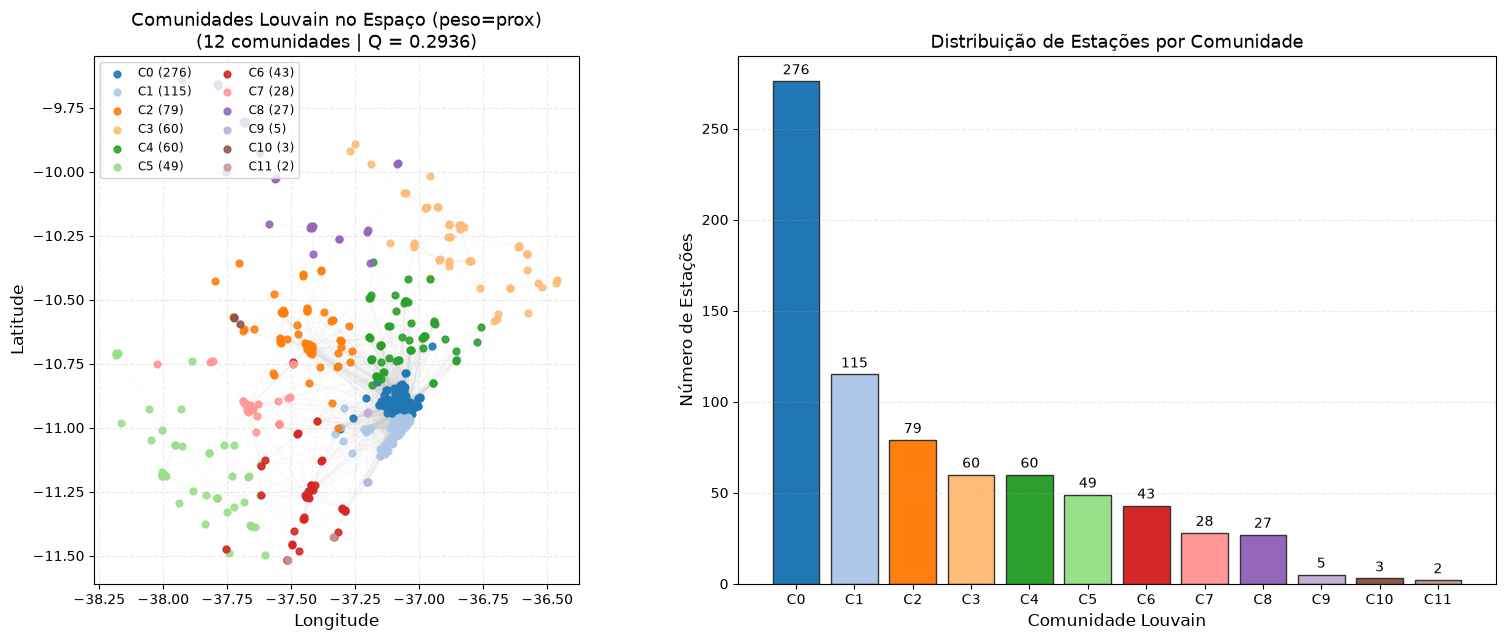

In [35]:
from matplotlib.collections import LineCollection

# 1. Cria peso de proximidade (inverso da distância) e executa o Louvain
for u, v, d in G.edges(data=True):
    d["prox"] = 1.0 / (d["weight"] + 0.1)

comunidades = nx.community.louvain_communities(G, weight="prox", resolution=0.6, seed=42)
comunidades = sorted(comunidades, key=len, reverse=True)
modularidade = nx.community.modularity(G, comunidades, weight="prox")

# Mapeia node_id -> comunidade (0 = maior comunidade)
mapa_comunidade = {}
for cid, nos in enumerate(comunidades):
    for u in nos:
        mapa_comunidade[u] = cid

df_centralidades["comunidade_louvain"] = df_centralidades["node_id"].map(mapa_comunidade)

print(f"Comunidades detectadas: {len(comunidades)} | Modularidade (Q): {modularidade:.4f}")
contagem_com = df_centralidades["comunidade_louvain"].value_counts().sort_index()
for cid, qtd in contagem_com.items():
    print(f"  - Comunidade {cid}: {qtd} estações")

# 2. Visualização: Mapa Geográfico das Comunidades + Tamanho por Comunidade
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), facecolor="white")

# Painel Esquerdo: Mapa espacial colorido por comunidade
ax = axes[0]
pos = {n: (d["longitude"], d["latitude"]) for n, d in G.nodes(data=True)}
segs = [[pos[u], pos[v]] for u, v in G.edges()]
ax.add_collection(LineCollection(segs, colors="#cccccc", linewidths=0.25, alpha=0.2, zorder=1))

cmap_name = "tab10" if len(comunidades) <= 10 else "tab20"
cmap = plt.get_cmap(cmap_name)
for cid in range(len(comunidades)):
    sub = df_centralidades[df_centralidades["comunidade_louvain"] == cid]
    ax.scatter(
        sub["longitude"], sub["latitude"],
        s=24, color=cmap(cid % cmap.N), alpha=0.9, zorder=3,
        label=f"C{cid} ({len(sub)})"
    )

ax.set_xlabel("Longitude", fontsize=12)
ax.set_ylabel("Latitude", fontsize=12)
ax.set_title(f"Comunidades Louvain no Espaço (peso=prox)\n({len(comunidades)} comunidades | Q = {modularidade:.4f})", fontsize=13)
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.25)
ax.legend(loc="upper left", fontsize=8.5, ncol=2, frameon=True)

# Painel Direito: Barras com quantidade de estações por comunidade
ax2 = axes[1]
cores_barras = [cmap(cid % cmap.N) for cid in contagem_com.index]
bars = ax2.bar([f"C{cid}" for cid in contagem_com.index], contagem_com.values, color=cores_barras, edgecolor="#333333")
for bar in bars:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 2, f"{int(h)}", ha="center", va="bottom", fontsize=10)
ax2.set_xlabel("Comunidade Louvain", fontsize=12)
ax2.set_ylabel("Número de Estações", fontsize=12)
ax2.set_title("Distribuição de Estações por Comunidade", fontsize=13)
ax2.grid(True, axis="y", linestyle="--", alpha=0.25)

plt.tight_layout()
plt.show()


In [29]:
import numpy as np
# 1. Lê o vetor binário de demandas
with open("../data/processed/vetor_demandas_se.bin", "rb") as f:
    N = np.frombuffer(f.read(4), dtype=np.int32)[0]
    demandas = np.frombuffer(f.read(), dtype=np.float64)
print(f"Demandas carregadas: {N} posições")

Demandas carregadas: 755 posições


In [30]:
# 2. Associa como atributo 'demanda' em cada nó do grafo G
# (os IDs dos nós em G já correspondem ao índice original em 'demandas')
for node in G.nodes():
    G.nodes[node]["demanda"] = float(demandas[node])
# 3. (Opcional) Adiciona também no DataFrame df_centralidades
df_centralidades["demanda"] = df_centralidades["node_id"].map(lambda n: float(demandas[n]))

,qtd_estacoes,total_antenas,demanda_media,demanda_mediana,demanda_max
comunidade_louvain,,,,,
12,12,297,134.519043,127.085271,194.000000
9,28,1146,129.538807,126.132859,165.585185
11,12,516,121.239308,129.578397,129.578397
13,11,594,119.024970,117.298611,170.448276
8,38,1716,109.586247,116.103070,165.585185
18,2,102,103.212121,103.212121,103.212121
15,4,201,101.465753,101.465753,101.465753
14,7,195,101.314527,104.548023,116.636364
7,41,1422,90.563065,59.996425,203.449275


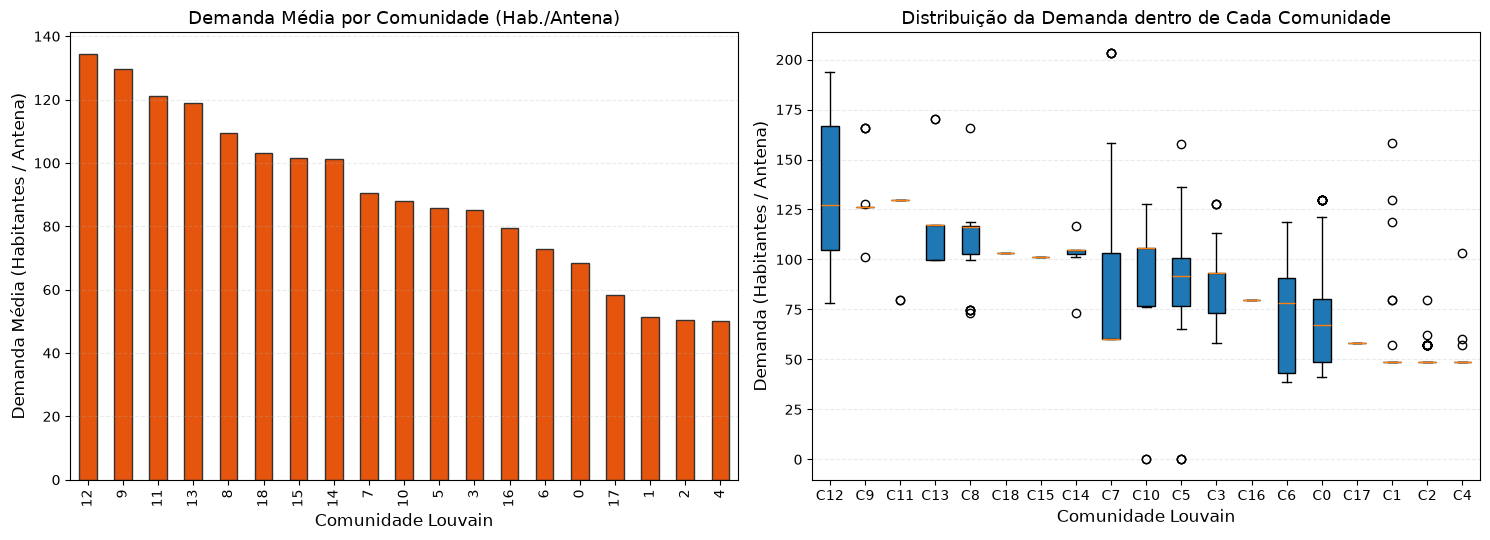

In [31]:
# 1. Tabela com o nível de demanda por comunidade
resumo_demanda = (
    df_centralidades.groupby("comunidade_louvain")
    .agg(
        qtd_estacoes=("node_id", "count"),
        total_antenas=("qtd_antenas", "sum"),
        demanda_media=("demanda", "mean"),
        demanda_mediana=("demanda", "median"),
        demanda_max=("demanda", "max"),
    )
    .sort_values("demanda_media", ascending=False)
)

display(resumo_demanda)

# 2. Plotagem: Média vs. Distribuição (Boxplot) por comunidade
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), facecolor="white")

# Painel Esquerdo: Demanda média ordenada
resumo_demanda["demanda_media"].plot(
    kind="bar", ax=axes[0], color="#e6550d", edgecolor="#333333"
)
axes[0].set_title("Demanda Média por Comunidade (Hab./Antena)", fontsize=13)
axes[0].set_xlabel("Comunidade Louvain", fontsize=12)
axes[0].set_ylabel("Demanda Média (Habitantes / Antena)", fontsize=12)
axes[0].grid(True, axis="y", linestyle="--", alpha=0.25)

# Painel Direito: Boxplot da distribuição interna de cada comunidade
ordem_cids = resumo_demanda.index.tolist()
dados_box = [
    df_centralidades[df_centralidades["comunidade_louvain"] == c]["demanda"].values
    for c in ordem_cids
]
axes[1].boxplot(dados_box, tick_labels=[f"C{c}" for c in ordem_cids], patch_artist=True)
axes[1].set_title("Distribuição da Demanda dentro de Cada Comunidade", fontsize=13)
axes[1].set_xlabel("Comunidade Louvain", fontsize=12)
axes[1].set_ylabel("Demanda (Habitantes / Antena)", fontsize=12)
axes[1].grid(True, axis="y", linestyle="--", alpha=0.25)

plt.tight_layout()
plt.show()